# Wearables vs depression/anxiety: comparison across all notebooks
Every AUROC below was parsed from the saved outputs of `SSAQS_baselines`, `NetHealth_final_clean` and `KAN_ODE_SSAQS`, not typed from the summary. Tasks differ between studies, so compare the **pattern** (past report vs wearable vs both), not raw numbers across studies.

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
import io, pandas as pd, numpy as np
import matplotlib.pyplot as plt
CSV = '''study,task,horizon_or_lead,model,auroc
NetHealth,depression,0,wave only,0.534
NetHealth,depression,0,past score only,0.764
NetHealth,depression,0,wave + past,0.77
NetHealth,depression,0,wearable S,0.624
NetHealth,depression,0,wearable P (vs own usual),0.541
NetHealth,depression,0,wave + wearable S,0.622
NetHealth,depression,0,wave + past + wearable S+P,0.766
NetHealth,depression,0,GBM wave + past,0.739
NetHealth,depression,0,GBM wave + past + wearable,0.733
NetHealth,depression,14,wave only,0.53
NetHealth,depression,14,past score only,0.766
NetHealth,depression,14,wave + past,0.773
NetHealth,depression,14,wearable S,0.605
NetHealth,depression,14,wearable P (vs own usual),0.531
NetHealth,depression,14,wave + wearable S,0.603
NetHealth,depression,14,wave + past + wearable S+P,0.759
NetHealth,depression,14,GBM wave + past,0.747
NetHealth,depression,14,GBM wave + past + wearable,0.748
NetHealth,depression,28,wave only,0.549
NetHealth,depression,28,past score only,0.771
NetHealth,depression,28,wave + past,0.78
NetHealth,depression,28,wearable S,0.576
NetHealth,depression,28,wearable P (vs own usual),0.524
NetHealth,depression,28,wave + wearable S,0.579
NetHealth,depression,28,wave + past + wearable S+P,0.747
NetHealth,depression,28,GBM wave + past,0.748
NetHealth,depression,28,GBM wave + past + wearable,0.759
NetHealth,anxiety,0,wave only,0.55
NetHealth,anxiety,0,past score only,0.826
NetHealth,anxiety,0,wave + past,0.85
NetHealth,anxiety,0,wearable S,0.513
NetHealth,anxiety,0,wearable P (vs own usual),0.598
NetHealth,anxiety,0,wave + wearable S,0.54
NetHealth,anxiety,0,wave + past + wearable S+P,0.775
NetHealth,anxiety,0,GBM wave + past,0.803
NetHealth,anxiety,0,GBM wave + past + wearable,0.753
NetHealth,anxiety,14,wave only,0.546
NetHealth,anxiety,14,past score only,0.822
NetHealth,anxiety,14,wave + past,0.849
NetHealth,anxiety,14,wearable S,0.561
NetHealth,anxiety,14,wearable P (vs own usual),0.599
NetHealth,anxiety,14,wave + wearable S,0.576
NetHealth,anxiety,14,wave + past + wearable S+P,0.788
NetHealth,anxiety,14,GBM wave + past,0.799
NetHealth,anxiety,14,GBM wave + past + wearable,0.762
NetHealth,anxiety,28,wave only,0.541
NetHealth,anxiety,28,past score only,0.834
NetHealth,anxiety,28,wave + past,0.859
NetHealth,anxiety,28,wearable S,0.603
NetHealth,anxiety,28,wearable P (vs own usual),0.584
NetHealth,anxiety,28,wave + wearable S,0.61
NetHealth,anxiety,28,wave + past + wearable S+P,0.802
NetHealth,anxiety,28,GBM wave + past,0.823
NetHealth,anxiety,28,GBM wave + past + wearable,0.777
NetHealth,anxiety_16,0,wave only,0.561
NetHealth,anxiety_16,0,past score only,0.808
NetHealth,anxiety_16,0,wave + past,0.841
NetHealth,anxiety_16,0,wearable S,0.575
NetHealth,anxiety_16,0,wearable P (vs own usual),0.55
NetHealth,anxiety_16,0,wave + wearable S,0.603
NetHealth,anxiety_16,0,wave + past + wearable S+P,0.797
NetHealth,anxiety_16,0,GBM wave + past,0.803
NetHealth,anxiety_16,0,GBM wave + past + wearable,0.781
NetHealth,anxiety_16,14,wave only,0.562
NetHealth,anxiety_16,14,past score only,0.807
NetHealth,anxiety_16,14,wave + past,0.84
NetHealth,anxiety_16,14,wearable S,0.579
NetHealth,anxiety_16,14,wearable P (vs own usual),0.576
NetHealth,anxiety_16,14,wave + wearable S,0.599
NetHealth,anxiety_16,14,wave + past + wearable S+P,0.778
NetHealth,anxiety_16,14,GBM wave + past,0.807
NetHealth,anxiety_16,14,GBM wave + past + wearable,0.774
NetHealth,anxiety_16,28,wave only,0.572
NetHealth,anxiety_16,28,past score only,0.821
NetHealth,anxiety_16,28,wave + past,0.854
NetHealth,anxiety_16,28,wearable S,0.607
NetHealth,anxiety_16,28,wearable P (vs own usual),0.544
NetHealth,anxiety_16,28,wave + wearable S,0.622
NetHealth,anxiety_16,28,wave + past + wearable S+P,0.804
NetHealth,anxiety_16,28,GBM wave + past,0.833
NetHealth,anxiety_16,28,GBM wave + past + wearable,0.791
NetHealth,bdi,0,wave only,0.526
NetHealth,bdi,0,past score only,0.768
NetHealth,bdi,0,wave + past,0.768
NetHealth,bdi,0,wearable S,0.599
NetHealth,bdi,0,wearable P (vs own usual),0.453
NetHealth,bdi,0,wave + wearable S,0.593
NetHealth,bdi,0,wave + past + wearable S+P,0.753
NetHealth,bdi,0,GBM wave + past,0.741
NetHealth,bdi,0,GBM wave + past + wearable,0.756
NetHealth,bdi,14,wave only,0.523
NetHealth,bdi,14,past score only,0.772
NetHealth,bdi,14,wave + past,0.773
NetHealth,bdi,14,wearable S,0.552
NetHealth,bdi,14,wearable P (vs own usual),0.481
NetHealth,bdi,14,wave + wearable S,0.552
NetHealth,bdi,14,wave + past + wearable S+P,0.723
NetHealth,bdi,14,GBM wave + past,0.755
NetHealth,bdi,14,GBM wave + past + wearable,0.695
NetHealth,bdi,28,wave only,0.516
NetHealth,bdi,28,past score only,0.77
NetHealth,bdi,28,wave + past,0.773
NetHealth,bdi,28,wearable S,0.572
NetHealth,bdi,28,wearable P (vs own usual),0.497
NetHealth,bdi,28,wave + wearable S,0.569
NetHealth,bdi,28,wave + past + wearable S+P,0.738
NetHealth,bdi,28,GBM wave + past,0.75
NetHealth,bdi,28,GBM wave + past + wearable,0.714
SSAQS-baselines,anxiety,1,heuristic: last self-report,0.66
SSAQS-baselines,anxiety,1,LR  past self-report only,0.737
SSAQS-baselines,anxiety,1,LR  wearable only,0.501
SSAQS-baselines,anxiety,1,LR  both,0.632
SSAQS-baselines,anxiety,1,GBM wearable only,0.465
SSAQS-baselines,anxiety,1,GBM both,0.652
SSAQS-baselines,anxiety,1,GRU wearable only,0.505
SSAQS-baselines,anxiety,3,heuristic: last self-report,0.654
SSAQS-baselines,anxiety,3,LR  past self-report only,0.746
SSAQS-baselines,anxiety,3,LR  wearable only,0.535
SSAQS-baselines,anxiety,3,LR  both,0.67
SSAQS-baselines,anxiety,3,GBM wearable only,0.515
SSAQS-baselines,anxiety,3,GBM both,0.673
SSAQS-baselines,anxiety,3,GRU wearable only,0.5
SSAQS-baselines,anxiety,7,heuristic: last self-report,0.659
SSAQS-baselines,anxiety,7,LR  past self-report only,0.744
SSAQS-baselines,anxiety,7,LR  wearable only,0.499
SSAQS-baselines,anxiety,7,LR  both,0.641
SSAQS-baselines,anxiety,7,GBM wearable only,0.475
SSAQS-baselines,anxiety,7,GBM both,0.637
SSAQS-baselines,anxiety,7,GRU wearable only,0.486
SSAQS-baselines,stress,1,heuristic: last self-report,0.655
SSAQS-baselines,stress,1,LR  past self-report only,0.706
SSAQS-baselines,stress,1,LR  wearable only,0.522
SSAQS-baselines,stress,1,LR  both,0.606
SSAQS-baselines,stress,1,GBM wearable only,0.554
SSAQS-baselines,stress,1,GBM both,0.644
SSAQS-baselines,stress,1,GRU wearable only,0.495
SSAQS-baselines,stress,3,heuristic: last self-report,0.627
SSAQS-baselines,stress,3,LR  past self-report only,0.706
SSAQS-baselines,stress,3,LR  wearable only,0.549
SSAQS-baselines,stress,3,LR  both,0.641
SSAQS-baselines,stress,3,GBM wearable only,0.577
SSAQS-baselines,stress,3,GBM both,0.633
SSAQS-baselines,stress,3,GRU wearable only,0.534
SSAQS-baselines,stress,7,heuristic: last self-report,0.603
SSAQS-baselines,stress,7,LR  past self-report only,0.677
SSAQS-baselines,stress,7,LR  wearable only,0.53
SSAQS-baselines,stress,7,LR  both,0.583
SSAQS-baselines,stress,7,GBM wearable only,0.566
SSAQS-baselines,stress,7,GBM both,0.594
SSAQS-baselines,stress,7,GRU wearable only,0.5
SSAQS-diagnostics,anxiety,0,past self-report,0.72
SSAQS-diagnostics,anxiety,0,wearable steps+activity,0.589
SSAQS-diagnostics,anxiety,0,wearable all,0.572
SSAQS-diagnostics,anxiety,0,past + steps+activity,0.715
SSAQS-diagnostics,anxiety,0,past + all,0.709
SSAQS-diagnostics,anxiety,1,past self-report,0.722
SSAQS-diagnostics,anxiety,1,wearable steps+activity,0.56
SSAQS-diagnostics,anxiety,1,wearable all,0.533
SSAQS-diagnostics,anxiety,1,past + steps+activity,0.718
SSAQS-diagnostics,anxiety,1,past + all,0.703
SSAQS-diagnostics,anxiety,3,past self-report,0.722
SSAQS-diagnostics,anxiety,3,wearable steps+activity,0.558
SSAQS-diagnostics,anxiety,3,wearable all,0.543
SSAQS-diagnostics,anxiety,3,past + steps+activity,0.722
SSAQS-diagnostics,anxiety,3,past + all,0.714
SSAQS-diagnostics,stress,0,past self-report,0.73
SSAQS-diagnostics,stress,0,wearable steps+activity,0.598
SSAQS-diagnostics,stress,0,wearable all,0.577
SSAQS-diagnostics,stress,0,past + steps+activity,0.728
SSAQS-diagnostics,stress,0,past + all,0.716
SSAQS-diagnostics,stress,1,past self-report,0.732
SSAQS-diagnostics,stress,1,wearable steps+activity,0.574
SSAQS-diagnostics,stress,1,wearable all,0.548
SSAQS-diagnostics,stress,1,past + steps+activity,0.724
SSAQS-diagnostics,stress,1,past + all,0.714
SSAQS-diagnostics,stress,3,past self-report,0.733
SSAQS-diagnostics,stress,3,wearable steps+activity,0.575
SSAQS-diagnostics,stress,3,wearable all,0.547
SSAQS-diagnostics,stress,3,past + steps+activity,0.737
SSAQS-diagnostics,stress,3,past + all,0.726
KAN-ODE,anxiety,3,GBM + past reports,0.66
KAN-ODE,anxiety,5,GBM + past reports,0.633
KAN-ODE,stress,3,GBM + past reports,0.617
KAN-ODE,stress,5,GBM + past reports,0.613
KAN-ODE,anxiety,3,GBM wearable-only,0.534
KAN-ODE,anxiety,5,GBM wearable-only,0.52
KAN-ODE,stress,3,GBM wearable-only,0.496
KAN-ODE,stress,5,GBM wearable-only,0.521
KAN-ODE,anxiety,3,KAN-ODE,0.502
KAN-ODE,anxiety,5,KAN-ODE,0.515
KAN-ODE,stress,3,KAN-ODE,0.543
KAN-ODE,stress,5,KAN-ODE,0.536
KAN-ODE,anxiety,3,Persistence (last 3 reports),0.736
KAN-ODE,anxiety,5,Persistence (last 3 reports),0.73
KAN-ODE,stress,3,Persistence (last 3 reports),0.706
KAN-ODE,stress,5,Persistence (last 3 reports),0.702
'''
df = pd.read_csv(io.StringIO(CSV))
df.groupby(['study','model']).auroc.agg(['count','min','max','mean']).round(3)

count    min    max   mean
study             model                                                   
KAN-ODE           GBM + past reports                4  0.613  0.660  0.631
                  GBM wearable-only                 4  0.496  0.534  0.518
                  KAN-ODE                           4  0.502  0.543  0.524
                  Persistence (last 3 reports)      4  0.702  0.736  0.718
NetHealth         GBM wave + past                  12  0.739  0.833  0.779
                  GBM wave + past + wearable       12  0.695  0.791  0.754
                  past score only                  12  0.764  0.834  0.794
                  wave + past                      12  0.768  0.859  0.811
                  wave + past + wearable S+P       12  0.723  0.804  0.769
                  wave + wearable S                12  0.540  0.622  0.589
                  wave only                        12  0.516  0.572  0.543
                  wearable P (vs own usual)        12  0.453  0.599  0.540
                  wearable S                       12  0.513  0.624  0.580
SSAQS-baselines   GBM both                          6  0.594  0.673  0.639
                  GBM wearable only                 6  0.465  0.577  0.525
                  GRU wearable only                 6  0.486  0.534  0.503
                  LR  both                          6  0.583  0.670  0.629
                  LR  past self-report only         6  0.677  0.746  0.719
                  LR  wearable only                 6  0.499  0.549  0.523
                  heuristic: last self-report       6  0.603  0.660  0.643
SSAQS-diagnostics past + all                        6  0.703  0.726  0.714
                  past + steps+activity             6  0.715  0.737  0.724
                  past self-report                  6  0.720  0.733  0.726
                  wearable all                      6  0.533  0.577  0.553
                  wearable steps+activity           6  0.558  0.598  0.576

## 1. Group models into three roles
`report` = uses past self-reports/persistence, `wearable` = wearable only, `both` = report + wearable.

In [2]:
ROLE = {
 ('NetHealth','past score only'):'report', ('NetHealth','wave + past'):'report',
 ('NetHealth','wearable S'):'wearable', ('NetHealth','wave + wearable S'):'wearable',
 ('NetHealth','wave + past + wearable S+P'):'both',
 ('SSAQS-baselines','LR  past self-report only'):'report', ('SSAQS-baselines','heuristic: last self-report'):'report',
 ('SSAQS-baselines','LR  wearable only'):'wearable', ('SSAQS-baselines','GBM wearable only'):'wearable', ('SSAQS-baselines','GRU wearable only'):'wearable',
 ('SSAQS-baselines','LR  both'):'both', ('SSAQS-baselines','GBM both'):'both',
 ('SSAQS-diagnostics','past self-report'):'report',
 ('SSAQS-diagnostics','wearable steps+activity'):'wearable', ('SSAQS-diagnostics','wearable all'):'wearable',
 ('SSAQS-diagnostics','past + steps+activity'):'both', ('SSAQS-diagnostics','past + all'):'both',
 ('KAN-ODE','Persistence (last 3 reports)'):'report', ('KAN-ODE','KAN-ODE'):'wearable',
 ('KAN-ODE','GBM wearable-only'):'wearable', ('KAN-ODE','GBM + past reports'):'both',
}
df['role'] = [ROLE.get((s,m)) for s,m in zip(df.study, df.model)]
d = df.dropna(subset=['role'])
tab = d.groupby(['study','role']).auroc.agg(['min','median','max','count']).round(3)
tab

min  median    max  count
study             role                                 
KAN-ODE           both      0.613   0.625  0.660      4
                  report    0.702   0.718  0.736      4
                  wearable  0.496   0.520  0.543      8
NetHealth         both      0.723   0.770  0.804     12
                  report    0.764   0.794  0.859     24
                  wearable  0.513   0.586  0.624     24
SSAQS-baselines   both      0.583   0.639  0.673     12
                  report    0.603   0.669  0.746     12
                  wearable  0.465   0.510  0.577     18
SSAQS-diagnostics both      0.703   0.717  0.737     12
                  report    0.720   0.726  0.733      6
                  wearable  0.533   0.566  0.598     12

## 2. Gap: past report vs wearable-only, and does adding wearable help?
Gap = median(report) minus median(wearable). A negative `delta_both_minus_report` means adding the wearable did not help.

In [3]:
rows=[]
for s,g in d.groupby('study'):
    med = g.groupby('role').auroc.median()
    rows.append(dict(study=s, report=med.get('report'), wearable=med.get('wearable'), both=med.get('both'),
        gap_report_minus_wearable=med.get('report')-med.get('wearable'),
        delta_both_minus_report=med.get('both')-med.get('report')))
gap = pd.DataFrame(rows).round(3); gap

,study,report,wearable,both,gap_report_minus_wearable,delta_both_minus_report
0,KAN-ODE,0.718,0.520,0.625,0.198,-0.093
1,NetHealth,0.794,0.586,0.770,0.208,-0.023
2,SSAQS-baselines,0.669,0.510,0.639,0.159,-0.030
3,SSAQS-diagnostics,0.726,0.566,0.717,0.160,-0.009


**Paired check** (same task and lead/horizon): how many times is `both` above `report`?

In [4]:
def paired(study, rep, both):
    a = df[(df.study==study)&(df.model==rep)].set_index(['task','horizon_or_lead']).auroc
    b = df[(df.study==study)&(df.model==both)].set_index(['task','horizon_or_lead']).auroc
    x = (b-a).dropna()
    return dict(study=study, report=rep, both=both, n=len(x), n_improved=int((x>0).sum()), mean_delta=round(x.mean(),3), worst=round(x.min(),3), best=round(x.max(),3))
pd.DataFrame([
 paired('NetHealth','wave + past','wave + past + wearable S+P'),
 paired('NetHealth','past score only','wave + past + wearable S+P'),
 paired('SSAQS-baselines','LR  past self-report only','LR  both'),
 paired('SSAQS-baselines','LR  past self-report only','GBM both'),
 paired('SSAQS-diagnostics','past self-report','past + steps+activity'),
 paired('SSAQS-diagnostics','past self-report','past + all'),
])

,study,report,both,n,n_improved,mean_delta,worst,best
0,NetHealth,wave + past,wave + past + wearable S+P,12,0,-0.042,-0.075,-0.004
1,NetHealth,past score only,wave + past + wearable S+P,12,1,-0.025,-0.051,0.002
2,SSAQS-baselines,LR past self-report only,LR both,6,0,-0.090,-0.105,-0.065
3,SSAQS-baselines,LR past self-report only,GBM both,6,0,-0.080,-0.107,-0.062
4,SSAQS-diagnostics,past self-report,past + steps+activity,6,1,-0.003,-0.008,0.004
5,SSAQS-diagnostics,past self-report,past + all,6,0,-0.013,-0.019,-0.007


## 3. Plot: AUROC range per study and role (dashed line = chance)

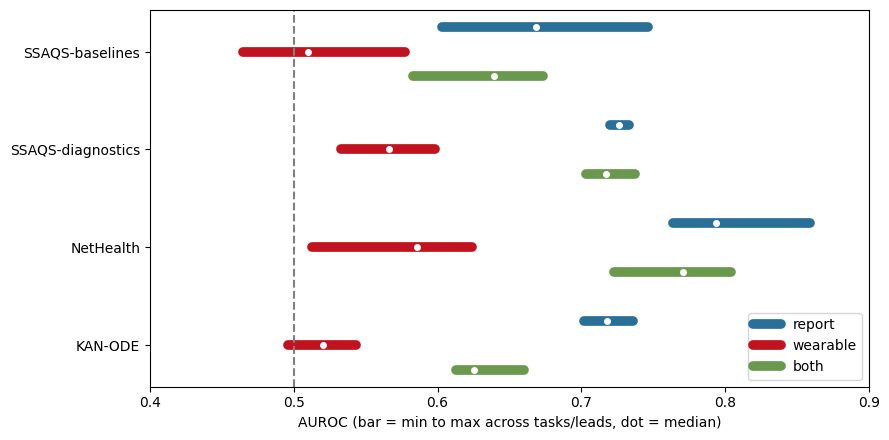

In [5]:
colors={'report':'#2a6f97','wearable':'#c1121f','both':'#6a994e'}
studies=['SSAQS-baselines','SSAQS-diagnostics','NetHealth','KAN-ODE']
fig,ax=plt.subplots(figsize=(9,4.5))
for i,s in enumerate(studies):
    for j,r in enumerate(['report','wearable','both']):
        v=d[(d.study==s)&(d.role==r)].auroc
        if len(v)==0: continue
        y=i+(j-1)*0.25
        ax.plot([v.min(),v.max()],[y,y],lw=7,color=colors[r],solid_capstyle='round',label=r if i==0 else None)
        ax.plot(v.median(),y,'wo',ms=4)
ax.axvline(0.5,ls='--',c='gray'); ax.set_yticks(range(len(studies))); ax.set_yticklabels(studies)
ax.set_xlabel('AUROC (bar = min to max across tasks/leads, dot = median)'); ax.set_xlim(0.4,0.9); ax.invert_yaxis()
ax.legend(loc='lower right'); plt.tight_layout(); plt.savefig('comparison_auroc.png',dpi=160); plt.show()

## 4. Non-AUROC findings (copied from the notebooks' printed tables)
These are typed here, each with the notebook it came from.

In [6]:
other = pd.DataFrame([
 ['SSAQS','Wearable sets adding to past report (delta CI above 0)','0 of 12','baselines: wearable-added-value'],
 ['SSAQS','Within-person correlations with CI excluding 0','8 of 60; sed_min rho 0.146 (anxiety), 0.161 (stress) at lead 0','baselines: within-person'],
 ['SSAQS','KAN vs LR (steps+activity+sleep), AUROC','KAN 0.515-0.543 vs LR 0.541-0.591','baselines: Part 3a'],
 ['SSAQS','Conformal coverage (target 0.90)','0.893-0.900; share not sure 0.61-0.66','baselines: Part 4'],
 ['NetHealth','Wearable gain over wave+demographics','depression +0.047 [-0.007, 0.079]; bdi +0.032 [-0.019, 0.080]','NetHealth cell 13'],
 ['NetHealth','Within-student change tests clearing 0','1 of 56 (bdi, sed_min, rho 0.096 [0.024, 0.182])','NetHealth cell 13'],
 ['NetHealth','KAN vs LR (14 window means)','depression 0.623 vs 0.629; bdi 0.581 vs 0.611; anxiety_16 0.571 vs 0.593','NetHealth cell 17'],
 ['NetHealth','Conformal coverage (target 0.90)','0.907, 0.912, 0.931; share not sure 0.57-0.64','NetHealth cell 15'],
 ['KAN-ODE','Early-warning detection rate (anxiety / stress)','KAN-ODE 0.22 / 0.29 vs persistence 0.80 / 0.73','KAN-ODE cell 27'],
 ['KAN-ODE','Ablation AP (anxiety 3d / stress 3d)','KAN-ODE 0.190/0.180; MLP 0.188/0.149; GRU 0.203/0.141; pooling 0.196/0.137','KAN-ODE cell 31'],
 ['KAN-ODE','Conformal coverage, all users','0.874-0.901','KAN-ODE cell 27'],
], columns=['study','finding','value','source'])
pd.set_option('display.max_colwidth',120); other

,study,finding,value,source
0,SSAQS,Wearable sets adding to past report (delta CI above 0),0 of 12,baselines: wearable-added-value
1,SSAQS,Within-person correlations with CI excluding 0,"8 of 60; sed_min rho 0.146 (anxiety), 0.161 (stress) at lead 0",baselines: within-person
2,SSAQS,"KAN vs LR (steps+activity+sleep), AUROC",KAN 0.515-0.543 vs LR 0.541-0.591,baselines: Part 3a
3,SSAQS,Conformal coverage (target 0.90),0.893-0.900; share not sure 0.61-0.66,baselines: Part 4
4,NetHealth,Wearable gain over wave+demographics,"depression +0.047 [-0.007, 0.079]; bdi +0.032 [-0.019, 0.080]",NetHealth cell 13
5,NetHealth,Within-student change tests clearing 0,"1 of 56 (bdi, sed_min, rho 0.096 [0.024, 0.182])",NetHealth cell 13
6,NetHealth,KAN vs LR (14 window means),depression 0.623 vs 0.629; bdi 0.581 vs 0.611; anxiety_16 0.571 vs 0.593,NetHealth cell 17
7,NetHealth,Conformal coverage (target 0.90),"0.907, 0.912, 0.931; share not sure 0.57-0.64",NetHealth cell 15
8,KAN-ODE,Early-warning detection rate (anxiety / stress),KAN-ODE 0.22 / 0.29 vs persistence 0.80 / 0.73,KAN-ODE cell 27
9,KAN-ODE,Ablation AP (anxiety 3d / stress 3d),KAN-ODE 0.190/0.180; MLP 0.188/0.149; GRU 0.203/0.141; pooling 0.196/0.137,KAN-ODE cell 31


## 5. Reading the numbers
- Past self-report beats wearable-only in every study.
- Adding wearables to the report does not help; see the paired table for how often it lowers AUROC.
- Wearable-only AUROC is about 0.50-0.62, and KAN-ODE is at chance.
- Sedentary minutes is the only channel that shows up in both datasets' within-person tests, and it is weak.
- Model type (LR, GBM, GRU, KAN, KAN-ODE) does not change the picture.